# 3.1 — Classification Fundamentals

## 3.1.1 — Classification vs. Regression

## 1. What Is the Difference?

Both regression and classification are **supervised machine learning** tasks. In both cases, a model learns from labeled training data containing features (`X`) and a target (`y`).

The main difference is the type of target we want to predict.

### Regression

Regression predicts a **numerical quantity**.

**Example:** Predicting a house's price based on its size, location, and number of bedrooms.

- Input features (`X`): House size, location, number of bedrooms
- Target (`y`): House price
- Example prediction: `8500000`

Common regression algorithms include `LinearRegression`, `Ridge`, `Lasso`, and `ElasticNet`.

Common evaluation metrics include MAE, MSE, RMSE, and R².

### Classification

Classification predicts a **category or class**.

**Example:** Predicting whether an email is spam or not spam.

- Input features (`X`): Email content, sender information, other relevant features
- Target (`y`): Spam or Not Spam
- Example prediction: `Spam`

Common classification algorithms include `LogisticRegression`, `KNeighborsClassifier`, `DecisionTreeClassifier`, and `RandomForestClassifier`.

Common evaluation metrics include accuracy, precision, recall, F1-score, and ROC-AUC.

## 2. Why Not Use Linear Regression for Classification?

Suppose we encode a student's result as:

- `0` = Fail
- `1` = Pass

Linear Regression could produce predictions such as `-0.3`, `0.65`, or `1.4`.

These outputs are not restricted to valid class labels. We could apply a threshold, such as predicting Pass when the output is at least `0.5`, but Linear Regression is not designed to model class probabilities appropriately.

Classification algorithms, such as Logistic Regression, are designed for categorical targets.

A classification model may calculate probabilities internally. For example, it might estimate a 90% probability that an email is spam and then predict the class `Spam`.

## 3. Comparison

| Aspect | Regression | Classification |
|---|---|---|
| Target | Numerical quantity | Category or class |
| Example | House price prediction | Spam detection |
| Output | A numerical value | A predicted class |
| Typical algorithm | `LinearRegression` | `LogisticRegression` |
| Common metrics | MAE, RMSE, R² | Accuracy, Precision, Recall, F1 |

## 4. Examples

| Problem | Type |
|---|---|
| Predicting a household's monthly electricity bill | Regression |
| Predicting whether a transaction is fraudulent | Classification |
| Predicting tomorrow's temperature | Regression |
| Identifying an image as a cat, dog, or bird | Classification |
| Predicting a student's final numerical score | Regression |
| Predicting whether a student passes or fails | Classification |

## 5. Key Takeaways

- **Regression predicts a numerical quantity.**
- **Classification predicts a category or class.**
- Both are supervised learning tasks that learn from labeled data.
- Classification models can use numerical scores or probabilities internally, even though their final predictions are classes.
- The type of target helps determine which algorithms and evaluation metrics are appropriate.


## 3.1.2 — Binary vs. Multiclass Classification

## 1. Binary Classification

Predicts **one of exactly two classes**.

Examples: Spam/Not Spam, Fraudulent/Legitimate, Pass/Fail.

## 2. Multiclass Classification

Predicts **one class from three or more possible classes**.

Examples: Cat/Dog/Bird, or classifying news as Sports/Politics/Business.

## 3. Simple Scikit-Learn Example

`LogisticRegression` supports both binary and multiclass classification.

```python
from sklearn.linear_model import LogisticRegression

# Binary classification
X_binary = [[1], [2], [3], [4]]
y_binary = [0, 0, 1, 1]

binary_model = LogisticRegression()
binary_model.fit(X_binary, y_binary)

print(binary_model.predict([[2.5]]))

# Multiclass classification
X_multi = [[1], [2], [3], [4], [5], [6]]
y_multi = [0, 0, 1, 1, 2, 2]

multi_model = LogisticRegression()
multi_model.fit(X_multi, y_multi)

print(multi_model.predict([[5.5]]))
```

Here:
- Binary classification has two classes: `0` and `1`.
- Multiclass classification has three classes: `0`, `1`, and `2`.
- `fit()` trains the model, while `predict()` predicts a class for new input.

These tiny datasets are only for demonstrating the API, not for building reliable predictive models.

## Key Takeaways

- **Binary:** Exactly two classes.
- **Multiclass:** Three or more classes, with one predicted class per example.
- The same algorithm can often handle both.


## 3.1.3 — Features, Labels, and Class Predictions

## 1. Features (`X`) and Labels (`y`)

- **Features (`X`):** Input information used to make predictions.
- **Labels (`y`):** The correct target classes the model learns to predict.

Example: Predicting whether a student passes an exam.

| Hours Studied (`X`) | Pass? (`y`) |
|---:|---|
| 1 | Fail |
| 2 | Fail |
| 4 | Pass |
| 6 | Pass |

In Scikit-Learn, `X` is usually a 2D array or DataFrame, while `y` is usually a 1D array or Series.

## 2. Training vs. Prediction

- `model.fit(X, y)`: Learns patterns from features and their known labels.
- `model.predict(X_new)`: Predicts classes for new inputs.

**True label:** The correct class in the dataset.

**Predicted class:** The class predicted by the model. Predictions can be incorrect, so we evaluate models using metrics such as accuracy, precision, recall, and F1-score.

## Key Takeaways

- `X` contains features (inputs).
- `y` contains labels (target classes).
- `fit()` trains the model.
- `predict()` predicts classes for new examples.


In [1]:
from sklearn.linear_model import LogisticRegression

# Features: hours studied
X = [[1], [2], [3], [4], [5], [6]]

# Labels: 0 = Fail, 1 = Pass
y = [0, 0, 0 , 1, 1, 1]

model = LogisticRegression()
model.fit(X, y)

prediction = model.predict([[3.5]])

print(prediction)

[1]


## 3.1.4 — The Classification Workflow

## 1. Typical Workflow

A classification task generally follows these steps:

1. **Load the dataset:** Obtain features (`X`) and labels (`y`).
2. **Split the data:** Separate training data from test data.
3. **Preprocess the data:** Handle missing values, encode categorical features, and scale features when necessary.
4. **Choose a classifier:** For example, Logistic Regression or a Decision Tree.
5. **Train the model:** Use `fit(X_train, y_train)`.
6. **Make predictions:** Use `predict(X_test)`.
7. **Evaluate performance:** Compare predictions with the true labels using appropriate metrics.

## 2. Why Split the Dataset?

Evaluating a model on the same examples used for training may give an overly optimistic picture of its performance on unseen data.

- **Training set:** Used to train the model.
- **Test set:** Used to evaluate the trained model on unseen examples.

An 80/20 split is a common starting point, with 80% for training and 20% for testing.

For classification, `train_test_split` can use `stratify=y` to preserve class proportions across the splits.

## 3. Important Practices

- Split the data before fitting the model.
- Train using `X_train` and `y_train`.
- Evaluate predictions against `y_test`.
- Fit preprocessing steps, such as a scaler, on training data only, then apply them to test data. Pipelines help prevent data leakage.
- Choose evaluation metrics appropriate to the problem.

## Key Takeaway

The goal is not merely to train a classifier, but to evaluate how well it generalizes to unseen data.



# 3.2 — Logistic Regression

## 3.2.1 — Introduction to Logistic Regression

## 1. Why Logistic Regression?

Linear Regression predicts numerical values, but classification requires predicting categories.

For example:
- `0` = Fail
- `1` = Pass

Linear Regression can produce values below `0` or above `1`, which are not valid probabilities.

**Logistic Regression estimates the probability that an example belongs to a class.**

## 2. How It Works

First, Logistic Regression calculates a linear score:

$$
z = w_1x_1 + w_2x_2 + \cdots + b
$$

It then applies the **sigmoid function** to convert that score into a probability:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The output is always between `0` and `1`.

Examples:

| Linear Score (\(z\)) | Probability (\(\sigma(z)\)) |
|---:|---:|
| -2 | 0.119 |
| 0 | 0.500 |
| 2 | 0.881 |

## 3. From Probability to Class

A common default decision threshold is `0.5`.

- Probability ≥ `0.5`: Predict class `1`.
- Probability < `0.5`: Predict class `0`.

For example, a predicted probability of `0.85` results in class `1` using the default threshold.

The threshold can be adjusted depending on the problem.

## 4. Why Is It Called Logistic Regression?

Logistic Regression models the **log-odds** of a class as a linear function of the input features, then uses the sigmoid function to estimate its probability.

Despite its name, it is a **classification algorithm**.

## Key Takeaways

- Linear Regression predicts numerical quantities.
- Logistic Regression estimates class probabilities.
- The sigmoid function converts a linear score into a probability between `0` and `1`.
- A decision threshold converts the probability into a class prediction.
- `0.5` is a common default threshold, not a universal rule.


## 3.2.2 Understanding `predict_proba()`

In classification, `predict()` returns the predicted class, while `predict_proba()` returns the estimated probability of each class.

- `predict()` tells us **which class the model predicts**.
- `predict_proba()` tells us **how probable each class is according to the model**.

For binary classification, the probabilities correspond to the classes in `model.classes_` order and sum to approximately 1.

For example, `[0.15, 0.85]` means the model estimates a 15% probability for class `0` and an 85% probability for class `1`.

By default, binary logistic regression predicts class `1` when its estimated probability reaches the default decision threshold of 0.5.

**Remember:** Predicted probabilities are estimates, not guarantees.

In [2]:
from sklearn.linear_model import LogisticRegression

# Features: hours studied
X = [[1], [2], [3], [4], [5], [6]]

# Labels: 0 = Fail, 1 = Pass
y = [0, 0, 0 , 1, 1, 1]

model = LogisticRegression()
model.fit(X, y)

prediction = model.predict([[3.5]])
prediction_prob = model.predict_proba([[3.5]])

print(prediction)
print(prediction_prob)


[1]
[[0.49996763 0.50003237]]


## 3.2.3 Decision Thresholds

A **decision threshold** determines how much probability a model needs to predict class `1` instead of class `0`.

For binary classification, the decision rule is:

$$
\hat{y} =
\begin{cases}
1, & \text{if } P(y=1 \mid x) \geq t \\
0, & \text{if } P(y=1 \mid x) < t
\end{cases}
$$

Where:
- \(\hat{y}\) = predicted class.
- \(P(y=1 \mid x)\) = estimated probability of class `1`.
- \(t\) = decision threshold, usually \(0.5\) by default.

**Example:** If the probability of class `1` is \(0.65\):
- Threshold \(0.3\) → predict class `1`.
- Threshold \(0.5\) → predict class `1`.
- Threshold \(0.7\) → predict class `0`.

### Why does the threshold matter?

- **Lower threshold:** Typically produces more positive predictions and may catch more actual positive cases, but can increase false positives.
- **Higher threshold:** Typically produces fewer positive predictions and may reduce false positives, but can miss more actual positive cases.

### Practical experiment

We used `make_classification()` to generate a synthetic dataset with two classes, `0` and `1`. These classes have no specific real-world meaning in our experiment.

We trained one Logistic Regression model and changed its decision threshold to observe how its predictions changed.

To inspect individual predictions, compare:

- **Probability:** The model's estimated probability of class `1`.
- **Predicted class:** The model's decision at the selected threshold.
- **Actual class:** The correct label provided by the dataset.

If the predicted class differs from the actual class, the model made a mistake on that sample.

**Key takeaway:** Changing the threshold changes how probabilities become class predictions; it does not retrain the model or change its predicted probabilities.

In [3]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification


X, y = make_classification(
    n_samples = 200,
    n_features = 4,
    n_informative = 3,
    n_redundant = 1,
    random_state = 42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

model = LogisticRegression()
model.fit(X_train, y_train)


#probabilities of class 1
probabilities = model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.5, 0.7]:
    predictions = (probabilities >= threshold).astype(int)

    print(f"Threshold: {threshold}")
    print("Positive predictions:", np.sum(predictions == 1))
    print("First 10 predictions:", predictions[:10])
    print()

for i in range(10):
    print(
        f"Sample {i}: "
        f"Probability of class 1 = {probabilities[i]:.3f}, "
        f"Predicted class = {predictions[i]}, "
        f"Actual class = {y_test[i]}"
    )

Threshold: 0.3
Positive predictions: 17
First 10 predictions: [0 1 1 1 0 1 1 0 1 0]

Threshold: 0.5
Positive predictions: 16
First 10 predictions: [0 1 1 1 0 1 1 0 1 0]

Threshold: 0.7
Positive predictions: 16
First 10 predictions: [0 1 1 1 0 1 1 0 1 0]

Sample 0: Probability of class 1 = 0.056, Predicted class = 0, Actual class = 0
Sample 1: Probability of class 1 = 0.999, Predicted class = 1, Actual class = 1
Sample 2: Probability of class 1 = 0.913, Predicted class = 1, Actual class = 1
Sample 3: Probability of class 1 = 0.992, Predicted class = 1, Actual class = 1
Sample 4: Probability of class 1 = 0.005, Predicted class = 0, Actual class = 0
Sample 5: Probability of class 1 = 0.999, Predicted class = 1, Actual class = 1
Sample 6: Probability of class 1 = 0.993, Predicted class = 1, Actual class = 1
Sample 7: Probability of class 1 = 0.106, Predicted class = 0, Actual class = 0
Sample 8: Probability of class 1 = 0.969, Predicted class = 1, Actual class = 1
Sample 9: Probability of 

## 3.2.4 Training a Logistic Regression Model

Logistic Regression learns patterns from labeled training data to predict the class of new samples.

**1. Load the dataset**

We use Scikit-Learn's built-in Breast Cancer Wisconsin dataset.

- `X` contains the input features (30 numerical measurements per tumor).
- `y` contains the target labels: `0` = malignant, `1` = benign.

**2. Split the dataset**

We divide the data into training and testing sets.

- `X_train`, `y_train`: Used to train the model.
- `X_test`, `y_test`: Reserved for evaluating the trained model.
- `test_size=0.2`: Uses 20% of the samples for testing.
- `stratify=y`: Preserves approximately the same class proportions in both sets.

**3. Train the model**

The `LogisticRegression()` constructor creates the model, and `model.fit(X_train, y_train)` learns its parameters from the training data.

**4. Make predictions**

- `model.predict(X_train)` generates predictions for the training samples.
- `model.predict(X_test)` generates predictions for unseen test samples.

The predictions are stored in `train_pred` and `test_pred`, respectively.

**5. Evaluate accuracy**

`accuracy_score()` compares predicted labels against the actual labels.

$$
\text{Accuracy} =
\frac{\text{Number of correct predictions}}
{\text{Total number of predictions}}
$$

**Results:**

- Training accuracy: approximately **95.60%**
- Testing accuracy: approximately **96.49%**

The test accuracy being slightly higher than the training accuracy is possible and does not automatically indicate a problem.

**Key takeaway:** The model learns from `X_train` and `y_train`, predicts using `X_test`, and is evaluated by comparing `test_pred` against `y_test`. The test set acts like an answer key that is kept separate during training.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_breast_cancer


data = load_breast_cancer()

X = data.data
y = data.target

print(f"Features : {data.feature_names}")
print(f"Classes : {data.target_names}")
print()

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

#Evaluate the model
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print(f"Training Accuracy : {accuracy_score(y_train, train_pred)}")
print(f"Testing Accuracy : {accuracy_score(y_test, test_pred)}")

Features : ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Classes : ['malignant' 'benign']

Training Accuracy : 0.9560439560439561
Testing Accuracy : 0.9649122807017544


## 3.2.5 Feature Scaling for Logistic Regression

Feature scaling transforms numerical features to comparable scales, helping Logistic Regression optimize its parameters more efficiently.

**Standardization** uses the following formula:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- \(x\) = original feature value.
- \(\mu\) = feature mean.
- \(\sigma\) = feature standard deviation.
- \(z\) = standardized value.

### Using `StandardScaler`

`StandardScaler()` creates a scaler object that can learn scaling parameters and transform numerical features.

- `scaler.fit(X_train)`: Learns the mean and standard deviation of each training feature.
- `scaler.transform(X_train)`: Scales the features using the learned parameters.
- `scaler.fit_transform(X_train)`: Performs both operations and returns the scaled data.

The original dataset remains unchanged; the transformed values are stored in a separate variable.

### Training Logistic Regression with Scaled Features

The workflow is:

1. Create the scaler using `StandardScaler()`.
2. Use `fit_transform()` on the training features to learn scaling parameters and scale the data.
3. Use `transform()` on the test features with the same learned parameters.
4. Train Logistic Regression using `model.fit(X_train_scaled, y_train)`.

**Why not use `fit_transform()` on the model?**

`fit_transform()` is a method of transformers such as `StandardScaler`, not `LogisticRegression`.

- `scaler.fit_transform(...)` learns scaling parameters and transforms features.
- `model.fit(...)` learns the Logistic Regression coefficients and intercept from the features and their target labels.

Using the training set's scaling parameters on the test set prevents data leakage during preprocessing.

**Key takeaway:** The scaler transforms the features; Logistic Regression learns from those transformed features. Feature scaling can improve optimization and make regularization more consistent across features, although it does not guarantee higher accuracy.

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#Model without scaling
model_unscaled = LogisticRegression(max_iter=10000)
model_unscaled.fit(X_train, y_train)

pred_unscaled = model_unscaled.predict(X_test)


#Scaling the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

#Model with scaling
model_scaled = LogisticRegression(max_iter=10000)
model_scaled.fit(X_train_scaled, y_train)

pred_scaled = model_scaled.predict(X_test_scaled)

print("Accuracy without scaling:",
      accuracy_score(y_test, pred_unscaled))

print("Accuracy with scaling:",
      accuracy_score(y_test, pred_scaled))

Accuracy without scaling: 0.9649122807017544
Accuracy with scaling: 0.9824561403508771


## 3.2.6 Multiclass Logistic Regression

### What is Multiclass Classification?

Multiclass classification predicts one class from **three or more mutually exclusive classes**.

For example, the Iris dataset contains three flower classes:

- Setosa (0)
- Versicolor (1)
- Virginica (2)

Unlike binary classification, which distinguishes between two classes, multiclass classification chooses among multiple possible classes.

### How Does Logistic Regression Handle Multiple Classes?

Scikit-learn's `LogisticRegression` supports multiclass classification. It learns to distinguish between the available classes and can estimate the probability of each class.

We can use:

- `fit()` to train the model.
- `predict()` to predict the class.
- `predict_proba()` to obtain the probability of each class.
- `classes_` to identify the class order used by the model.

### Understanding Predicted Probabilities

Suppose `model.classes_` returns:

```python
[0, 1, 2]
```

And `predict_proba()` returns:

```python
[[0.02, 0.95, 0.03]]
```

The probabilities correspond to classes 0, 1, and 2, respectively.

| Class | Probability |
|---|---:|
| Setosa (0) | 0.02 |
| Versicolor (1) | 0.95 |
| Virginica (2) | 0.03 |

The model predicts **Versicolor (class 1)** because it has the highest probability.

The probabilities across the classes sum to approximately 1.

### Important Points

- Multiclass classification is supported by both Scikit-learn and deep learning frameworks such as TensorFlow.
- Traditional ML models, including Logistic Regression, KNN, Decision Trees, Random Forests, and SVMs, can be implemented using Scikit-learn.
- In multiclass classification, `predict()` generally selects the class with the highest predicted probability.
- Unlike binary classification, there is no single universal 0.5 threshold applied to all classes.
- Feature scaling is often helpful for Logistic Regression, so fit the scaler on the training data and use it to transform both training and test data.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

# Load dataset
data = load_iris()
X = data.data
y = data.target

print("Features:", data.feature_names)
print("Classes:", data.target_names)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#Scaler Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

model = LogisticRegression(max_iter=10000)
model.fit(X_train_scaled, y_train)


#Evaluate
y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))

print()

probabilities = model.predict_proba(X_test_scaled)

np.set_printoptions(suppress=True, precision=7)

print(probabilities[:5])
print(y_pred[:5])
print(f"Class Order : {model.classes_}")

print()

#How predict() is picking the class

print(f"Predicted Class : {y_pred[:5]}")
print(f"Predicted probabilities : {probabilities[:5]}")

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Accuracy: 0.9666666666666667

[[0.9783172 0.0216824 0.0000005]
 [0.0023823 0.3144947 0.683123 ]
 [0.1007828 0.886713  0.0125041]
 [0.0592765 0.9265408 0.0141826]
 [0.9894312 0.0105686 0.0000002]]
[0 2 1 1 0]
Class Order : [0 1 2]

Predicted Class : [0 2 1 1 0]
Predicted probabilities : [[0.9783172 0.0216824 0.0000005]
 [0.0023823 0.3144947 0.683123 ]
 [0.1007828 0.886713  0.0125041]
 [0.0592765 0.9265408 0.0141826]
 [0.9894312 0.0105686 0.0000002]]


# 3.3 Classification Evaluation

Classification evaluation helps us measure how well a classification model performs and understand the types of mistakes it makes.

A model's performance should not be judged by accuracy alone. Depending on the problem, false positives and false negatives may have very different consequences.

## 3.3.1 — Why Accuracy Alone Can Be Misleading

### What Is Accuracy?

Accuracy measures the proportion of predictions that the model classifies correctly.

$$
\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Number of Predictions}}
$$

For example, if a model correctly predicts 90 out of 100 samples, its accuracy is 90%.

### The Problem with Imbalanced Datasets

An imbalanced dataset contains significantly different numbers of samples belonging to different classes.

Consider a disease-detection dataset containing 1,000 people:

- 990 people do not have the disease (class 0).
- 10 people have the disease (class 1).

Suppose a model predicts class 0 for every person.

- It correctly classifies all 990 people without the disease.
- It incorrectly classifies all 10 people with the disease.

Its accuracy is:

$$
\text{Accuracy} = \frac{990}{1000} = 0.99 = 99\%
$$

Despite achieving 99% accuracy, the model fails to detect any person with the disease.

### Key Takeaway

**High accuracy does not always mean a good classifier.** When a dataset is imbalanced, a model can achieve high accuracy by predicting only the majority class.

Therefore, we need additional evaluation metrics to understand how well a model identifies each class and what types of mistakes it makes.

We will learn about the confusion matrix, precision, recall, F1-score, and other classification evaluation metrics in the following sections.

In [7]:
from sklearn.metrics import accuracy_score
import numpy as np

# Actual labels: 990 people without disease, 10 with disease
y_true = np.array([0] * 990 + [1] * 10)

# Model predicts no disease for everyone
y_pred = np.zeros(1000, dtype=int)

print(f"Accuracy : {accuracy_score(y_true, y_pred)}")


Accuracy : 0.99


## 3.3.2 — Confusion Matrix

A **confusion matrix** evaluates a classification model by comparing its actual labels with its predicted labels. It shows how many predictions were correct and incorrect for each class.

### 1. Creating a Confusion Matrix

We can use Scikit-learn's `confusion_matrix()` function.

```python
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print(cm)
```

For our disease-detection experiment, the output is:

```text
[[990   0]
 [ 10   0]]
```

Here:
- `0` = No disease
- `1` = Has disease

### 2. How to Read a Confusion Matrix

In Scikit-learn, **rows represent actual classes, and columns represent predicted classes**.

| Actual / Predicted | No disease (0) | Disease (1) |
|---|---:|---:|
| No disease (0) | 990 | 0 |
| Disease (1) | 10 | 0 |

Each cell tells us how many samples belong to a particular combination of actual and predicted labels.

- **990:** People without the disease correctly predicted as having no disease.
- **0:** People without the disease incorrectly predicted as having the disease.
- **10:** People with the disease incorrectly predicted as having no disease.
- **0:** People with the disease correctly identified as having the disease.

The matrix reveals that the model misses all 10 disease cases, despite achieving 99% accuracy.

### 3. The Four Outcomes of Binary Classification

The four cells have specific names:

| Term | Meaning | Our result |
|---|---|---:|
| True Negative (TN) | Actual 0, predicted 0 | 990 |
| False Positive (FP) | Actual 0, predicted 1 | 0 |
| False Negative (FN) | Actual 1, predicted 0 | 10 |
| True Positive (TP) | Actual 1, predicted 1 | 0 |

Remember:

- **True** means the prediction is correct.
- **False** means the prediction is incorrect.
- **Positive** refers to class 1.
- **Negative** refers to class 0.

A **False Negative** means the model misses a real positive case. A **False Positive** means the model incorrectly predicts a positive case.

### 4. Calculating Accuracy from the Confusion Matrix

The diagonal cells contain the correct predictions: TN and TP.

$$
\text{Accuracy} = \frac{TN+TP}{TN+FP+FN+TP}
$$

For our experiment:

$$
\text{Accuracy} = \frac{990+0}{990+0+10+0} = 0.99 = 99\%
$$

Although accuracy is 99%, the model fails to detect every person with the disease. This demonstrates why accuracy alone can be misleading.

### 5. Visualizing the Confusion Matrix

Scikit-learn can display the matrix as a plot.

```python
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease", "Disease"]
).plot()

plt.show()
```

The visualization makes it easier to compare correct and incorrect predictions.

### 6. Confusion Matrices for Multiclass Classification

Confusion matrices also work for classification problems with three or more classes.

For example, our Iris dataset contains three classes:
- Setosa (0)
- Versicolor (1)
- Virginica (2)

Its confusion matrix has three rows and three columns. Each row represents an actual flower class, and each column represents a predicted class.

```python
from sklearn.metrics import confusion_matrix

cm_iris = confusion_matrix(y_test, predictions)
print(cm_iris)
```

The diagonal cells show correctly classified flowers, while off-diagonal cells show which classes the model confused with one another.

### Key Takeaways

- A confusion matrix compares actual labels with predicted labels.
- Rows represent actual classes; columns represent predicted classes.
- Diagonal cells represent correct predictions; off-diagonal cells represent mistakes.
- TN, FP, FN, and TP describe the four outcomes of binary classification.
- Confusion matrices work for both binary and multiclass classification.
- Accuracy can be calculated from the confusion matrix, but additional metrics are needed to understand different types of errors.

In [8]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Actual labels: 990 people without disease, 10 with disease
y_true = np.array([0] * 990 + [1] * 10)

# Model predicts no disease for everyone
y_pred = np.zeros(1000, dtype=int)

cm = confusion_matrix(y_true, y_pred)
print(cm)

[[990   0]
 [ 10   0]]


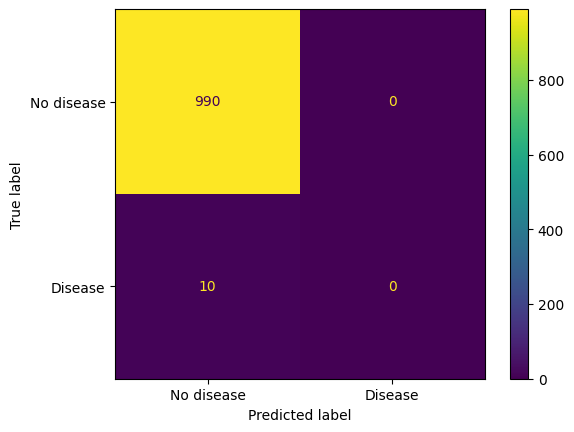

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease", "Disease"]
).plot();

### Multiclass Confusion Matrix

(150, 4)
(30, 4)
(30,)

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Accuracy : 96.67%

Feature Names : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Names : ['setosa' 'versicolor' 'virginica']



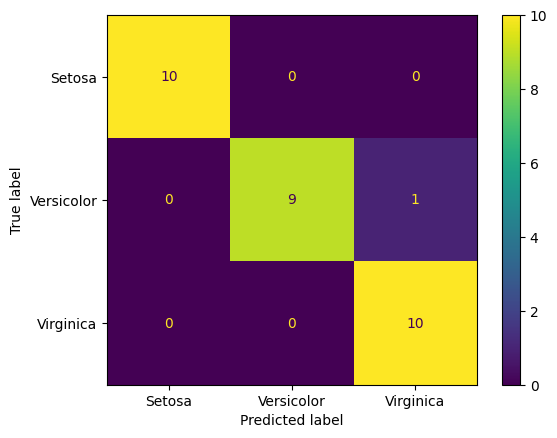

In [10]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

Iris = load_iris()
X, y = Iris.data, Iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print(X.shape)     
print(X_test.shape)   
print(y_test.shape) 

print() 

print(cm)

print()

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy : {accuracy * 100:.2f}%")
print()

print(f"Feature Names : {Iris.feature_names}")
print(f"Target Names : {Iris.target_names}")

print()

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Setosa", "Versicolor", "Virginica"]
).plot();

## 3.3.3 — Precision and Recall

### 1. Why Precision and Recall?

Accuracy tells us the proportion of all predictions that are correct. However, it does not explain what types of mistakes a classification model makes.

**Precision** and **Recall** help us evaluate a model's performance for individual classes.

### 2. Precision

Precision answers:

*Of all samples predicted as a particular class, how many actually belong to that class?*

$$
\text{Precision}=\frac{TP}{TP+FP}
$$

- **TP (True Positive):** Correctly predicted positive samples.
- **FP (False Positive):** Samples incorrectly predicted as positive.

Higher precision means fewer false-positive predictions.

### 3. Recall

Recall answers:

*Of all samples that actually belong to a particular class, how many did the model correctly identify?*

$$
\text{Recall}=\frac{TP}{TP+FN}
$$

- **FN (False Negative):** Actual positive samples incorrectly predicted as negative.

Higher recall means fewer false negatives.

### 4. Precision vs Recall

- **Precision:** How reliable are the model's positive predictions?
- **Recall:** How many actual positive samples did the model find?

For example, in disease detection, high recall helps reduce missed disease cases, while high precision helps reduce false alarms.

### 5. Calculating Precision and Recall in Scikit-Learn

```python
from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_test, y_pred, average=None)
recall = recall_score(y_test, y_pred, average=None)
```

`average=None` calculates a separate precision and recall score for each class rather than combining them into one score.

To display the results clearly:

```python
import pandas as pd

pd.DataFrame({
    "Class": iris.target_names,
    "Precision": precision,
    "Recall": recall
})
```

### 6. Interpreting Our Iris Experiment

Our confusion matrix was:

$$
\begin{bmatrix}
10 & 0 & 0\\
0 & 9 & 1\\
0 & 0 & 10
\end{bmatrix}
$$

Our results:

| Class | Precision | Recall |
|---|---:|---:|
| Setosa | 100% | 100% |
| Versicolor | 100% | 90% |
| Virginica | 90.91% | 100% |

**Interpretation:**

- **Setosa:** All 10 actual Setosa flowers were correctly classified, and all predictions of Setosa were correct.
- **Versicolor:** All predictions of Versicolor were correct, but the model identified only 9 of the 10 actual Versicolor flowers.
- **Virginica:** The model identified all 10 actual Virginica flowers, but one Versicolor flower was incorrectly predicted as Virginica.

The same misclassification affected two metrics differently: Versicolor's recall decreased, while Virginica's precision decreased.

### Key Takeaways

- Accuracy measures overall classification correctness.
- Precision measures the reliability of predictions for a class.
- Recall measures how many actual samples of a class were correctly identified.
- Precision and recall can differ for the same class.
- In multiclass classification, scikit-learn can calculate these metrics separately for every class using `average=None`.


In [11]:
from sklearn.metrics import precision_score, recall_score
import pandas as pd

precision = precision_score(y_test, y_pred, average=None)
recall = recall_score(y_test, y_pred, average=None)

pd.DataFrame({
    "Class" : Iris.target_names,
    "Precision" : precision,
    "Recall" : recall
})

,Class,Precision,Recall
0,setosa,1.000000,1.0
1,versicolor,1.000000,0.9
2,virginica,0.909091,1.0


- **Precision:** The predicted things are correct, but some predictions might be wrong.
- **Recall:** The model correctly predicts some things, but it might miss some actual ones.

## 3.3.4 — F1-Score

### 1. What Is F1-Score?

F1-score combines **precision and recall** into a single metric using their harmonic mean.

It is useful when both precision and recall matter and we want to evaluate them together.

### 2. Formula

$$
F_1 = 2 \times \frac{\text{Precision}\times\text{Recall}}{\text{Precision}+\text{Recall}}
$$

F1-score ranges from 0 to 1, or 0% to 100%.

### 3. Why Do We Need F1-Score?

Precision and recall measure different aspects of a model:

- **Precision:** Of the samples predicted as positive, how many were actually positive?
- **Recall:** Of all actual positive samples, how many did the model correctly identify?

A model can have high precision but low recall, or high recall but low precision. F1-score combines both into one metric.

### 4. Example: Comparing Two Models

Suppose two models predict whether an email is spam.

| Model | Precision | Recall |
|---|---:|---:|
| Model A | 100% | 50% |
| Model B | 75% | 75% |

Model A's spam predictions are always correct, but it misses many actual spam emails. Model B makes some incorrect spam predictions but identifies more of the actual spam.

- Model A F1-score: 66.67%
- Model B F1-score: 75%

Model B has the higher F1-score because it balances precision and recall better.

### 5. When Should We Use F1-Score?

The appropriate metric depends on the consequences of different mistakes.

**Example 1: Disease Detection**

- False Positive: A healthy person is incorrectly flagged as potentially having a disease.
- False Negative: A person who has the disease is incorrectly classified as healthy.

Missing a genuine disease case can delay treatment and have serious consequences. Therefore, **recall may be prioritized** to reduce missed cases. Precision still matters because false alarms can cause unnecessary tests, anxiety, and costs.

**Example 2: Rain Prediction**

- False Positive: The model predicts rain, but it does not rain. Someone might carry an umbrella unnecessarily.
- False Negative: The model predicts no rain, but it rains. Someone might get wet.

For ordinary rain prediction, if both mistakes have roughly similar costs, **F1-score can be a reasonable metric** because it balances precision and recall.

For severe storms or flood warnings, missing a dangerous event can have serious consequences, so recall may become more important.

**Example 3: Fraud Detection**

- False Positive: A legitimate transaction is flagged as fraudulent, potentially inconveniencing the customer.
- False Negative: A fraudulent transaction is classified as legitimate, allowing the fraud to go undetected.

Depending on the costs of missed fraud and unnecessary transaction blocks, a business might prioritize recall, precision, or a balance between them.

### 6. Important Properties

- A higher F1-score indicates a better balance between precision and recall.
- If either precision or recall is low, F1-score is reduced.
- F1-score reaches 100% only when both precision and recall are 100%.
- The harmonic mean penalizes an imbalance between precision and recall more than the arithmetic mean.
- F1-score does not directly account for true negatives (TN).
- A higher F1-score does not automatically mean a model is best for every problem.

### 7. Our Iris Experiment

| Class | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Setosa | 100% | 100% | 100% |
| Versicolor | 100% | 90% | 94.74% |
| Virginica | 90.91% | 100% | 95.24% |

- **Setosa:** Both precision and recall are perfect, so F1-score is 100%.
- **Versicolor:** The model missed one actual Versicolor flower, reducing recall and F1-score.
- **Virginica:** One Versicolor flower was incorrectly predicted as Virginica, reducing precision and F1-score.

### Key Takeaways

- **Precision:** Measures the reliability of positive predictions.
- **Recall:** Measures how many actual positive samples were identified.
- **F1-score:** Combines precision and recall into one metric.
- Use F1-score when both precision and recall matter.
- Prioritize precision or recall when one type of error is substantially more costly.
- Always choose evaluation metrics based on the real-world problem and its consequences.

In [12]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred, average=None)

pd.DataFrame({
    "Class" : Iris.target_names,
    "Precision" : precision,
    "Recall" : recall,
    "F1 Score" : f1
})

,Class,Precision,Recall,F1 Score
0,setosa,1.000000,1.0,1.000000
1,versicolor,1.000000,0.9,0.947368
2,virginica,0.909091,1.0,0.952381


## 3.3.5 — Specificity and False Positive Rate (FPR)

### 1. Specificity

Specificity measures how many actual negative samples the model correctly identifies as negative.

**Formula:**

$$
\text{Specificity}=\frac{TN}{TN+FP}
$$

- **TN (True Negative):** Actual negatives correctly predicted as negative.
- **FP (False Positive):** Actual negatives incorrectly predicted as positive.

**Example — Disease Detection:**

Suppose we test 100 healthy people:

- 90 are correctly identified as healthy (TN = 90).
- 10 are incorrectly predicted to have the disease (FP = 10).

$$
\text{Specificity}=\frac{90}{90+10}=90\%
$$

The model correctly identifies 90% of the healthy people.

### 2. False Positive Rate (FPR)

FPR measures the proportion of actual negative samples that the model incorrectly predicts as positive.

**Formula:**

$$
\text{FPR}=\frac{FP}{FP+TN}
$$

Using the same example:

$$
\text{FPR}=\frac{10}{10+90}=10\%
$$

The model incorrectly flags 10% of the healthy people as potentially having the disease.

### 3. Relationship Between Specificity and FPR

Specificity and FPR use the same denominator but count different outcomes.

$$
\text{Specificity}=1-\text{FPR}
$$

Therefore, if specificity is 90%, FPR is 10%.

- Higher specificity means fewer false positives among actual negatives.
- Lower FPR means fewer actual negatives are incorrectly classified as positive.

### 4. When Are These Metrics Useful?

- **Specificity:** Useful when we want to measure how well a model identifies actual negative cases.
- **FPR:** Useful when we want to measure how often actual negative cases are incorrectly flagged as positive.

**Example — Fraud Detection:**

- False Positive: A legitimate transaction is incorrectly flagged as fraudulent.
- True Negative: A legitimate transaction is correctly identified as legitimate.

A low FPR can help reduce unnecessary transaction reviews and inconvenience to customers.

### 5. Comparing the Classification Metrics

| Metric | Formula | Main question |
|---|---|---|
| Precision | \(TP/(TP+FP)\) | Of predicted positives, how many were correct? |
| Recall (TPR) | \(TP/(TP+FN)\) | Of actual positives, how many were found? |
| Specificity | \(TN/(TN+FP)\) | Of actual negatives, how many were correctly identified? |
| FPR | \(FP/(FP+TN)\) | Of actual negatives, how many were incorrectly flagged? |

### 6. Important Things to Remember

- Specificity and FPR require actual negative samples.
- If there are no actual negative samples, FPR and specificity are undefined.
- Specificity and FPR are complementary: their sum is 1.
- A model predicting every sample as negative can achieve 100% specificity while missing every positive sample. Therefore, specificity should not be evaluated alone.
- In multiclass classification, these metrics can be calculated for an individual class using a one-versus-rest approach.

**Key Takeaway:** Specificity measures the correct identification of actual negatives, while FPR measures the incorrect identification of actual negatives as positive.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)


# Treat malignant (0) as the positive class
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tp, fn, fp, tn = cm.ravel()

specificity = tn / (tn + fp)
fpr = fp / (fp + tn)

print(f"Specificity : {specificity * 100}")
print(f"FPR : {fpr * 100}")

Specificity : 98.61111111111111
FPR : 1.3888888888888888


## 3.3.6 — ROC Curve and AUC

## 1. Why Do We Need ROC and AUC?

In classification, we have already learned several evaluation metrics:

- **Accuracy:** What proportion of all predictions are correct?
- **Precision:** Of all predicted positive cases, how many are actually positive?
- **Recall (TPR):** Of all actual positive cases, how many did the model identify?
- **F1-score:** How well does the model balance precision and recall?
- **Specificity:** Of all actual negative cases, how many did the model correctly identify?
- **False Positive Rate (FPR):** Of all actual negative cases, how many did the model incorrectly classify as positive?

These metrics are useful, but most of them are calculated from predictions made at a particular classification threshold.

For example, Logistic Regression commonly uses a threshold of `0.5`:

- If the predicted probability of the positive class is at least `0.5`, predict positive.
- Otherwise, predict negative.

But what if we change the threshold to `0.3` or `0.7`?

The model may detect more positive cases, but it may also produce more false positives. We need a way to understand this trade-off across different thresholds.

**The ROC curve and AUC help us evaluate a classifier's ability to distinguish between positive and negative classes across thresholds.**

### Example: Cancer Detection

Suppose we build a model to detect malignant tumors.

If the threshold is too high, the model may fail to identify some malignant tumors.

If the threshold is too low, the model may incorrectly flag more benign tumors as malignant.

ROC helps us examine this trade-off, while AUC summarizes the model's overall ability to distinguish the two classes.

---

## 2. Understanding Classification Thresholds

Logistic Regression can predict probabilities using `predict_proba()`.

Suppose a patient receives a predicted probability of malignancy of `0.65`.

| Threshold | Decision | Reason |
|---|---|---|
| `0.50` | Malignant | `0.65 >= 0.50` |
| `0.60` | Malignant | `0.65 >= 0.60` |
| `0.70` | Benign | `0.65 < 0.70` |

The model's probability remains `0.65`. Only the threshold changes.

### What Happens When We Change the Threshold?

**Lower threshold:**

- The model becomes more willing to predict positive.
- It generally identifies more actual positive cases.
- True Positive Rate (TPR) usually increases.
- False Positive Rate (FPR) may also increase.

**Higher threshold:**

- The model becomes less willing to predict positive.
- It generally predicts positive less often.
- TPR usually decreases.
- FPR usually decreases.

These are general tendencies; the actual rates depend on the dataset and predicted scores.

The threshold lets us control how willing the classifier is to predict the positive class.

---

## 3. Understanding TPR and FPR

The ROC curve uses two metrics that we have already learned.

### 3.1 True Positive Rate (TPR)

TPR is also called **Recall** or **Sensitivity**.

It measures the proportion of actual positive cases correctly identified by the model.

\[
TPR = \frac{TP}{TP+FN}
\]

Where:

- TP = True Positives
- FN = False Negatives

For example, suppose there are 100 actual malignant cases, and the model correctly identifies 95 of them.

\[
TPR = \frac{95}{95+5} = 0.95
\]

The model identifies 95% of the actual malignant cases.

A higher TPR is generally desirable.

### 3.2 False Positive Rate (FPR)

FPR measures the proportion of actual negative cases incorrectly predicted as positive.

\[
FPR = \frac{FP}{FP+TN}
\]

Where:

- FP = False Positives
- TN = True Negatives

Suppose there are 100 actual benign cases, and the model incorrectly flags 5 as malignant.

\[
FPR = \frac{5}{5+95} = 0.05
\]

The FPR is 5%.

A lower FPR is generally desirable.

### Remember the Difference

| Metric | Denominator | Question |
|---|---|---|
| TPR / Recall | All actual positives | How many actual positives did we identify? |
| FPR | All actual negatives | How many actual negatives did we incorrectly flag? |

TPR concerns actual positive cases. FPR concerns actual negative cases.

---

## 4. What Is an ROC Curve?

ROC stands for **Receiver Operating Characteristic**.

An ROC curve plots:

- **X-axis:** False Positive Rate (FPR)
- **Y-axis:** True Positive Rate (TPR)

Each point on the curve represents the model's performance at a particular classification threshold.

The curve is created by calculating TPR and FPR at many different thresholds.

### Example

Suppose a model produces the following results at three thresholds:

| Threshold | TPR | FPR | ROC point (FPR, TPR) |
|---|---:|---:|---|
| 0.90 | 0.60 | 0.02 | (0.02, 0.60) |
| 0.50 | 0.90 | 0.10 | (0.10, 0.90) |
| 0.20 | 0.98 | 0.25 | (0.25, 0.98) |

Interpretation:

- At threshold `0.90`, the model catches 60% of positive cases and incorrectly flags 2% of negative cases.
- At threshold `0.50`, it catches 90% of positive cases but incorrectly flags 10% of negative cases.
- At threshold `0.20`, it catches 98% of positive cases but incorrectly flags 25% of negative cases.

Notice the trade-off: lowering the threshold helps the model catch more positive cases, but it also creates more false positives.

**The ROC curve visualizes this trade-off across thresholds.**

---

## 5. How to Interpret the ROC Curve

A good ROC curve generally moves toward the **top-left corner**.

The ideal point is:

\[
(FPR,TPR)=(0,1)
\]

This means:

- FPR = 0: No actual negative cases are incorrectly flagged.
- TPR = 1: All actual positive cases are correctly identified.

In practice, a model may not achieve this point.

### The Three Important Regions

**Top-left region:**

- High TPR
- Low FPR
- Generally desirable performance

**Diagonal region:**

- TPR is approximately equal to FPR.
- Represents random-level discrimination on average.

**Below the diagonal:**

- The model may rank positive cases below negative cases.
- Reversing its scores could improve its ranking ability.

A curve above the diagonal generally indicates better-than-random ranking.

---

## 6. What Is a Random Classifier?

In our plot, we draw a dashed diagonal using:

```python
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)
```

This line runs from `(0, 0)` to `(1, 1)`.

It is a **reference baseline**, not a second model that our code has trained.

A classifier that assigns random scores independently of the true labels has an expected ROC curve along this diagonal.

At points on the diagonal:

\[
TPR = FPR
\]

For example:

| FPR | TPR |
|---:|---:|
| 0.0 | 0.0 |
| 0.2 | 0.2 |
| 0.5 | 0.5 |
| 0.8 | 0.8 |
| 1.0 | 1.0 |

A random classifier has an expected AUC of `0.5`.

The diagonal helps us visually compare our model against random-level ranking performance.

---

## 7. What Is AUC?

AUC stands for **Area Under the Curve**. In this topic, it means the area under the ROC curve.

The ROC curve shows how TPR and FPR change across thresholds. AUC summarizes the curve into a single number.

### General Interpretation

| AUC | General interpretation |
|---:|---|
| `1.0` | Perfect ranking of positive cases above negative cases |
| `0.9` | Excellent discrimination in many applications |
| `0.8` | Good discrimination in many applications |
| `0.7` | Moderate discrimination |
| `0.5` | Random-level ranking performance |
| Below `0.5` | Worse-than-random ranking, potentially due to reversed score direction |

These descriptions are general guidelines, not universal standards.

An AUC of `0.8` may be useful in one application but insufficient in another. The acceptable value depends on the problem and the consequences of errors.

### What Does AUC = 0.90 Actually Mean?

AUC has a useful probabilistic interpretation.

If we randomly select one actual positive case and one actual negative case, an AUC of `0.90` means:

**There is a 90% probability that the model assigns a higher positive-class score to the positive case than to the negative case.**

Ties count as half in this interpretation.

For our cancer example, that means the model usually assigns a higher malignancy probability to a malignant tumor than to a benign tumor.

This does **not** mean that 90% of all predictions are correct. Accuracy measures something different.

---

## 8. Understanding Ranking

Ranking means ordering samples from the highest predicted positive-class probability to the lowest.

Suppose our model predicts the following probabilities of malignancy:

| Patient | Actual diagnosis | Predicted probability |
|---|---|---:|
| A | Malignant | 0.90 |
| B | Benign | 0.20 |
| C | Malignant | 0.70 |
| D | Benign | 0.10 |

Ranked from highest to lowest malignancy probability:

1. Patient A — 0.90
2. Patient C — 0.70
3. Patient B — 0.20
4. Patient D — 0.10

This is a perfect ranking for these four patients because both malignant cases have higher scores than both benign cases.

There are four positive-negative pairs:

| Pair | Is the positive case ranked higher? |
|---|---|
| A vs. B | Yes |
| A vs. D | Yes |
| C vs. B | Yes |
| C vs. D | Yes |

All four pairs are correctly ranked.

\[
AUC = \frac{4}{4} = 1.0
\]

Now suppose patient C receives a malignancy probability of `0.15`. Patient C would rank below both benign patients. Only two of the four pairs would be correctly ranked.

\[
AUC = \frac{2}{4} = 0.5
\]

This illustrates why AUC measures ranking ability.

### Ranking vs. Classification

**Classification** asks whether a patient is predicted to be malignant or benign at a chosen threshold.

**Ranking** asks whether malignant patients tend to receive higher malignancy scores than benign patients.

A model can have good ranking ability even when its predictions at the default threshold of `0.5` are not ideal.

AUC evaluates ranking across thresholds rather than evaluating only one threshold.

---

## 9. Why We Use Both ROC and AUC

### ROC Curve

The ROC curve helps us:

- Visualize the trade-off between TPR and FPR.
- Understand how performance changes with different thresholds.
- Identify thresholds that may offer a useful balance between detecting positives and limiting false alarms.

### AUC

AUC helps us:

- Summarize the ROC curve with a single number.
- Compare the discrimination ability of different classifiers.
- Evaluate ranking ability without committing to one classification threshold.

### Important Limitation

AUC does not tell us which threshold is best for every application.

For example, in cancer screening, missing a malignant case may be much more costly than incorrectly flagging a benign case. We may therefore prefer a threshold with high TPR, even if its FPR is somewhat higher.

The threshold should reflect the application's requirements and error costs.

AUC also does not measure probability calibration. A model may rank cases well while its predicted probabilities are poorly calibrated.

---

## 10. Implementing ROC and AUC in Scikit-Learn

We will use the Breast Cancer Wisconsin dataset and Logistic Regression.

In this dataset:

- `0` = malignant
- `1` = benign

For our evaluation, we want to treat **malignant as the positive class**.

### Step 1: Train Logistic Regression

If you have already created the training and test sets, you can reuse them.

```python
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=10000)
model.fit(X_train_scaled, y_train)
```

We scale because Logistic Regression generally benefits from comparable feature scales.

We fit the scaler only on training data to avoid data leakage. The test set is transformed using the parameters learned from the training set.

### Step 2: Obtain the Probability of Malignancy

```python
y_proba = model.predict_proba(X_test_scaled)[:, 0]
```

`predict_proba()` returns one probability column per class, in the order specified by `model.classes_`.

For this dataset, the class order is `[0, 1]`.

Therefore:

- `[:, 0]` selects the probability of malignant (`0`).
- `[:, 1]` selects the probability of benign (`1`).

We select column `0` because we want to evaluate malignancy detection.

### Step 3: Calculate the ROC Curve

```python
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba,
    pos_label=0
)
```

Arguments:

- `y_test`: actual labels.
- `y_proba`: predicted probabilities of malignancy.
- `pos_label=0`: specifies that malignant is the positive class.

The function returns:

- `fpr`: False Positive Rates at the evaluated thresholds.
- `tpr`: True Positive Rates at those thresholds.
- `thresholds`: the corresponding probability cutoffs.

These arrays provide the coordinates for plotting the ROC curve.

### Step 4: Calculate AUC

```python
from sklearn.metrics import roc_auc_score

auc_score = roc_auc_score(
    (y_test == 0).astype(int),
    y_proba
)

print(f"AUC: {auc_score:.3f}")
```

Why do we transform `y_test`?

The original labels are:

- `0` = malignant
- `1` = benign

For binary `roc_auc_score()`, scikit-learn normally treats label `1` as positive.

The expression:

```python
(y_test == 0).astype(int)
```

converts malignant labels to `1` and benign labels to `0` for this calculation.

For example:

| Original label | Meaning | Transformed label |
|---:|---|---:|
| `0` | Malignant | `1` |
| `1` | Benign | `0` |

Now the transformed target and `y_proba` both represent malignancy as the positive class.

**Important:** This transformation does not modify your original dataset.

### Step 5: Plot the ROC Curve

```python
import matplotlib.pyplot as plt

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()
```

Explanation:

**First `plt.plot()`**

- `fpr` supplies the X-coordinates.
- `tpr` supplies the Y-coordinates.
- `label` adds the model name and formatted AUC to the legend.
- `:.3f` displays AUC to three decimal places.

**Second `plt.plot()`**

- `[0, 1]` supplies the X-coordinates.
- `[0, 1]` supplies the Y-coordinates.
- `linestyle="--"` makes the line dashed.
- `label="Random classifier"` identifies the reference line in the legend.

The second line does not train a model. It simply draws the diagonal baseline.

---

## 11. A Positive-Class Mistake We Must Avoid

The original target mapping is:

- `0` = malignant
- `1` = benign

Suppose we calculate:

```python
y_proba = model.predict_proba(X_test_scaled)[:, 0]
```

These are malignancy probabilities.

For the ROC curve, we must specify:

```python
roc_curve(y_test, y_proba, pos_label=0)
```

For AUC, we can instead transform the actual labels:

```python
roc_auc_score((y_test == 0).astype(int), y_proba)
```

These two approaches are consistent.

### Why the Original AUC Was Approximately 0.005

Initially, we calculated AUC using the original `y_test` labels and malignancy probabilities:

```python
roc_auc_score(y_test, y_proba, labels=[0, 1])
```

The problem was that binary `roc_auc_score()` normally treats class `1` as positive, but our scores represented class `0`.

The score direction and positive-class interpretation were inconsistent.

After transforming the labels, the AUC became approximately `0.995`.

\[
1 - 0.00463 \approx 0.99537
\]

The model did not suddenly improve. We corrected how the AUC was calculated.

**Remember:** The scores passed to AUC must represent the class treated as positive.

---

## 12. Important Limitations of ROC and AUC

1. **AUC is not accuracy.** An AUC of `0.95` does not mean that 95% of predictions are correct.

2. **AUC does not select the best threshold automatically.** Threshold selection depends on the application's requirements.

3. **AUC does not measure calibration.** A model can rank cases correctly while producing inaccurate probability estimates.

4. **A high test AUC does not guarantee generalization.** Evaluate performance on appropriate unseen data and, when suitable, use cross-validation.

5. **ROC can be less informative when positive cases are extremely rare.** In highly imbalanced problems, a Precision-Recall curve may provide additional useful information.

6. **Always check the positive class and score direction.** A mismatch can produce an AUC below `0.5` even when the model's ROC curve appears excellent.

---

## 13. Key Takeaways

- ROC stands for Receiver Operating Characteristic.
- A ROC curve plots FPR on the X-axis and TPR on the Y-axis.
- Each point represents a classification threshold.
- Lowering the threshold generally increases TPR but can also increase FPR.
- The top-left corner represents the ideal ROC operating point.
- A random-score classifier has an expected AUC of `0.5`.
- AUC summarizes the model's ranking ability across thresholds.
- AUC of `1.0` indicates perfect ranking; `0.5` indicates random-level ranking.
- AUC is not accuracy and does not determine the best threshold by itself.
- In scikit-learn, keep the positive-class labels consistent with the probability scores.

### The Simplest Way to Remember

**ROC:** How does the trade-off between detecting positive cases and generating false alarms change across thresholds?

**AUC:** How well does the model rank positive cases above negative cases overall?

**Why do we use them?** To evaluate and compare a classifier's discrimination ability across thresholds, rather than relying only on its predictions at one threshold.

AUC : 0.9953703703703705


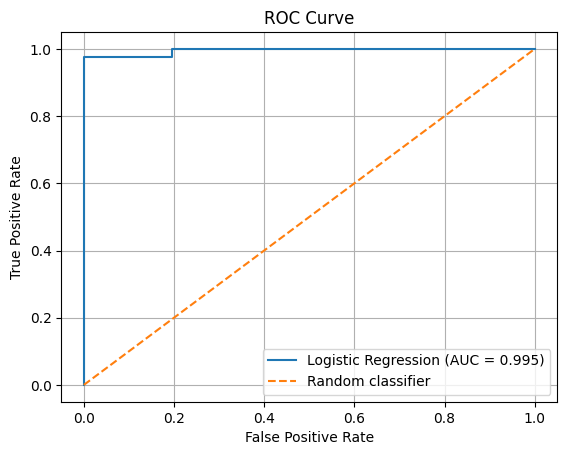

In [14]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=10000)
model.fit(X_train_scaled, y_train)


y_proba = model.predict_proba(X_test_scaled)[:, 0]



fpr, tpr, thresholds = roc_curve(
    y_test, y_proba, pos_label=0
)


auc_score = roc_auc_score(
    (y_test == 0).astype(int), y_proba, labels=[0, 1]
)


print(f"AUC : {auc_score}")


plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)

## 3.3.7 — Classification Report

## 1. What Is a Classification Report?

Scikit-learn's `classification_report()` summarizes several classification metrics in one output:

- **Precision:** Of all samples predicted as a class, how many actually belong to that class?
- **Recall:** Of all actual samples belonging to a class, how many did the model identify?
- **F1-score:** Harmonic mean of precision and recall.
- **Support:** Number of actual test samples belonging to each class.

## 2. Implementation

```python
from sklearn.metrics import classification_report

y_pred = model.predict(X_test_scaled)

print(classification_report(y_test, y_pred))
```

- `y_test`: Actual labels.
- `y_pred`: Predicted class labels.
- `classification_report()`: Compares the actual and predicted labels and summarizes the metrics.

## 3. Understanding the Output

Example:

```text
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
       benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114
```

These are illustrative values.

In the Breast Cancer dataset:
- `0` = malignant
- `1` = benign

Each class has its own precision, recall, and F1-score. **Support** tells us that the test set contains 42 malignant and 72 benign samples in this example.

- **Accuracy:** Proportion of all test predictions that are correct.
- **Macro average:** Calculates the metric for each class, then gives each class equal weight.
- **Weighted average:** Averages the class metrics, weighting each class by its support.

Macro and weighted averages are useful when comparing performance across classes, especially with imbalanced datasets.

## 4. Important Note

The classification report uses predicted class labels, unlike ROC/AUC, which uses probability or decision scores to evaluate performance across thresholds.

The report is convenient because it calculates multiple metrics in one function call. Learning the individual metrics helps us understand and interpret its output.

## Key Takeaway

`classification_report()` provides a compact summary of a classifier's precision, recall, F1-score, support, accuracy, and average scores.

In [15]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test_scaled)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



# 3.4 — K-Nearest Neighbors (KNN)
## 3.4.1 — KNN Fundamentals & Distance Calculation

### 1. What Is KNN?

K-Nearest Neighbors (KNN) is a supervised learning algorithm used for classification and regression.

For classification, it predicts a new sample's class by examining the labels of its K nearest training samples.

Unlike Logistic Regression, KNN does not learn coefficients during training. It stores the training data and uses distances to make predictions.

### 2. How Does KNN Work?

1. Choose the number of neighbors, K.
2. Calculate the distances between the new sample and training samples.
3. Select the K nearest samples.
4. Predict the majority class among those neighbors.

**Example:** If K = 5 and four neighbors are benign while one is malignant, KNN predicts benign.

### 3. Euclidean Distance

Euclidean distance measures the straight-line distance between two samples.

For two features:

$$
d(x,z)=\sqrt{(x_1-z_1)^2+(x_2-z_2)^2}
$$

For n features:

$$
d(x,z)=\sqrt{\sum_{j=1}^{n}(x_j-z_j)^2}
$$

KNN uses Euclidean distance by default.

### 4. Why Is Feature Scaling Important?

Features with larger numerical ranges can dominate distance calculations. For example, income values may be much larger than age values.

Therefore, KNN generally benefits from feature scaling, such as `StandardScaler`.

**Important:** Fit the scaler on training data only, then transform both training and test data to prevent data leakage.

### 5. Implementing KNN

```python
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)
```

- `n_neighbors=5`: considers the five nearest training samples.
- `fit()`: prepares the model using the training data.
- `predict()`: predicts classes for new samples.

### 6. Advantages and Limitations

**Advantages**
- Simple and intuitive.
- Can capture nonlinear decision boundaries.
- Requires little explicit model training.

**Limitations**
- Prediction can be slow on large datasets.
- Sensitive to feature scaling and irrelevant features.
- Performance depends on K and the distance metric.

**Key takeaway:** KNN classifies a sample using its nearest neighbors. Distance calculation, feature scaling, and the choice of K are central to its performance.


In [16]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report


data = load_breast_cancer()

X, y = data.data, data.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)


print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred,
                            target_names=data.target_names))

Accuracy: 0.956140350877193
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 3.4.2 — Choosing the Optimal K

### 1. Why Does K Matter?

In KNN, K determines how many nearest training samples participate in the majority vote.

- **Small K:** Sensitive to noise and individual samples; may overfit.
- **Large K:** Produces smoother decision boundaries but may underfit.
- **Intermediate K:** May provide a better balance between overfitting and underfitting.

The best value depends on the dataset.

### 2. Experimental Results

Using the breast cancer dataset, we tested different K values.

| K | Test Accuracy |
|---:|---:|
| 1 | 93.86% |
| 3 | 98.25% |
| 5 | 95.61% |
| 7 | 97.37% |
| 9 | 97.37% |
| 11 | 97.37% |
| 15 | 97.37% |
| 21 | 96.49% |

**Best result:** K = 3 achieved 98.25% accuracy, correctly classifying 112 out of 114 test samples.

These results apply to the current test split and do not guarantee that K = 3 will perform best on unseen data.

### 3. Precision and Recall

Accuracy alone may not be sufficient when different classification errors have different consequences.

- **Precision:** Of the samples predicted as a particular class, how many actually belong to that class?
- **Recall:** Of the actual samples belonging to a particular class, how many did the model identify?

For malignant cases, recall measures how many actual malignant samples were detected, while precision measures how many malignant predictions were correct.

### 4. Selecting K More Reliably

Repeatedly selecting K based on test accuracy can lead to overestimating model performance.

A better approach is to:

1. Compare K values using a validation set or cross-validation.
2. Select K based on validation performance.
3. Evaluate the final model on the test set.

### Key Takeaway

The optimal K balances sensitivity to local patterns against excessive smoothing. Use validation or cross-validation to select K rather than relying solely on test accuracy.

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = [1, 3, 5, 7, 9, 11, 15, 21]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    print(f"For k = {k}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred,
                            target_names=data.target_names))
    print("\n\n")
    

For k = 1
Accuracy: 0.9385964912280702
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114




For k = 3
Accuracy: 0.9824561403508771
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114




For k = 5
Accuracy: 0.956140350877193
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   mac

## 3.4.3 — Training Accuracy vs. Validation Accuracy: Overfitting and Underfitting

### 1. Training Accuracy vs. Validation Accuracy

- **Training accuracy:** Measures how accurately the model predicts samples from the data used to train it.
- **Validation accuracy:** Measures performance on separate data used to compare models and tune hyperparameters.

Comparing these scores helps us understand how well the model fits the training data and generalizes to unseen samples.

### 2. Overfitting

Overfitting occurs when a model fits the training data too closely, including noise or unusual patterns, and performs worse on unseen data.

**Typical pattern:**
- High training accuracy.
- Lower validation accuracy.
- A large gap between the two scores.

In KNN, a very small K, such as K = 1, can lead to overfitting because predictions are highly sensitive to individual training samples.

### 3. Underfitting

Underfitting occurs when a model fails to capture important patterns in the data.

**Typical pattern:**
- Low training accuracy.
- Low validation accuracy.

In KNN, a very large K may cause underfitting because the model considers a broader neighborhood that can include samples from different classes.

### 4. Good Generalization

A model that generalizes well achieves strong validation performance while maintaining a reasonably small gap between training and validation accuracy.

However, a small gap alone does not guarantee a good model; both scores should be sufficiently high.

### 5. Our Experimental Results

Using the breast cancer dataset:

| K | Training Accuracy | Validation Accuracy |
|---:|---:|---:|
| 1 | 100.00% | 94.51% |
| 3 | 98.08% | 96.70% |
| 5 | 97.53% | 96.70% |
| 7 | 97.25% | 97.80% |
| 9 | 97.53% | 96.70% |
| 11 | 97.25% | 94.51% |
| 15 | 96.98% | 95.60% |
| 21 | 96.15% | 94.51% |

**Observation:** K = 1 shows a clear training-validation gap, consistent with overfitting. K = 7 achieves the highest validation accuracy among the tested values.

These results apply to our particular validation split. Cross-validation can provide a more reliable basis for choosing K.

### 6. Important Considerations

- Do not select hyperparameters based solely on test accuracy.
- Use validation data or cross-validation to compare models.
- Keep the test set separate for final evaluation.
- When using feature scaling, fit the scaler only on the training portion of each split to avoid data leakage.

### Key Takeaway

Training accuracy shows how well KNN fits its training data, while validation accuracy helps assess generalization. Comparing them helps identify potential overfitting and underfitting and guides the selection of K.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

k_values = [1, 3, 5, 7, 9, 11, 15, 21]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_sub, y_train_sub)

    train_pred = knn.predict(X_train_sub)
    val_pred = knn.predict(X_val)

    train_acc = accuracy_score(y_train_sub, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    print(
        f"K={k:2d} | "
        f"Train={train_acc:.4f} | "
        f"Validation={val_acc:.4f}"
    )

K= 1 | Train=1.0000 | Validation=0.9451
K= 3 | Train=0.9808 | Validation=0.9670
K= 5 | Train=0.9753 | Validation=0.9670
K= 7 | Train=0.9725 | Validation=0.9780
K= 9 | Train=0.9753 | Validation=0.9670
K=11 | Train=0.9725 | Validation=0.9451
K=15 | Train=0.9698 | Validation=0.9560
K=21 | Train=0.9615 | Validation=0.9451


## 3.4.4 — Cross-Validation for Choosing K

### 1. What Is Cross-Validation?

Cross-validation is a technique for evaluating a model across multiple data splits to estimate how well it generalizes to unseen data.

In **K-fold cross-validation**, the training data is divided into K folds. The model is trained and validated multiple times, with each fold serving as the validation set once.

Note: The K in K-fold cross-validation is different from the K in KNN's `n_neighbors` parameter.

### 2. How 5-Fold Cross-Validation Works

1. Divide the training data into five folds.
2. Train on four folds and validate on the remaining fold.
3. Repeat five times, using a different validation fold each time.
4. Calculate the mean validation score across all five folds.

### 3. Why Use Cross-Validation?

A model's performance can vary depending on which samples are used for validation.

Cross-validation provides a more reliable comparison than relying on a single validation split. It helps us select hyperparameters such as the number of neighbors in KNN.

### 4. Implementing Cross-Validation

Scikit-Learn provides `cross_val_score()` to evaluate a model across multiple folds.

- `StratifiedKFold`: Creates folds while attempting to preserve class proportions.
- `cross_val_score()`: Returns the evaluation score for each fold.
- `scores.mean()`: Calculates the mean score.
- `scores.std()`: Measures the variability of scores across folds.

### 5. Using a Pipeline

Combining `StandardScaler` and KNN in a `Pipeline` ensures that scaling is fitted separately on each training fold.

This prevents validation-fold information from influencing the scaler's fitted statistics and helps avoid data leakage.

### 6. Our Experimental Results

Using five-fold cross-validation on the breast cancer training data:

| Metric | K = 3 | K = 7 |
|---|---:|---:|
| Mean accuracy | 96.26% | 96.26% |
| Standard deviation | 0.88 percentage points | 2.04 percentage points |

Both values achieved approximately the same mean accuracy, but K = 3 showed less variation across the five folds.

These results suggest that K = 3 is a reasonable candidate, although further comparisons are needed before selecting the final model.

### Key Takeaway

Cross-validation evaluates a model across multiple splits, reducing dependence on a single validation set. Use it to compare K values, then reserve the test set for the final evaluation.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=7))
])


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


scores = cross_val_score(
    knn_pipeline, X_train, y_train, cv=cv, scoring="accuracy"
)

print("Fold scores:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold scores: [0.967033  0.978022  0.9450549 0.9340659 0.989011 ]
Mean accuracy: 0.9626373626373625
Standard deviation: 0.020381579110979577


## 3.4.5 — Finding the Best K with GridSearchCV

### 1. What Is GridSearchCV?

`GridSearchCV` is a Scikit-Learn tool for hyperparameter tuning. It evaluates different parameter combinations using cross-validation and selects the configuration with the best mean validation score.

For KNN, we use it to find a suitable value for `n_neighbors`.

### 2. How Does GridSearchCV Work?

1. Define the hyperparameter values to test.
2. Evaluate each configuration using cross-validation.
3. Calculate the mean validation score for each configuration.
4. Select the configuration with the highest mean score.
5. Refit the selected model on the entire training dataset.

For example, we can test K values of 1, 3, 5, 7, 9, 11, 15, 21, 25, and 31 using five-fold cross-validation.

This requires 50 cross-validation fits: 10 candidate values multiplied by 5 folds. With the default `refit=True`, Scikit-Learn then performs one additional fit on the full training dataset.

### 3. Tuning Hyperparameters Inside a Pipeline

We combine `StandardScaler` and `KNeighborsClassifier` in a `Pipeline`.

This ensures that scaling is fitted separately within each cross-validation training fold, preventing validation-fold information from influencing the scaler's fitted statistics.

To tune a parameter inside a pipeline, Scikit-Learn uses the format:

`step_name__parameter_name`

For example, `knn__n_neighbors` refers to the `n_neighbors` parameter of the pipeline step named `knn`.

### 4. Mean CV Accuracy vs. Test Accuracy

These two metrics serve different purposes.

| Mean CV Accuracy | Test Accuracy |
|---|---|
| Evaluates performance across multiple validation folds | Evaluates the selected model on a separate, held-out test set |
| Helps compare models and choose K | Helps assess the final selected model |
| Calculated using training data divided into folds | Calculated using test data not used for model selection |
| Used during hyperparameter tuning | Used for final evaluation |

**Mean CV accuracy helps us choose; test accuracy helps us assess our choice.**

The scores may differ because the validation folds and test set contain different samples. Neither score guarantees future performance.

### 5. Why Must We Keep the Test Set Separate?

Repeatedly selecting hyperparameters based on test accuracy allows information from the test set to influence model selection, making the final evaluation less independent.

The correct workflow is:

1. Use cross-validation on the training data to select K.
2. Refit the selected pipeline on the full training dataset.
3. Evaluate the selected model on the untouched test set.

### 6. Important Attributes of GridSearchCV

- `best_params_`: The hyperparameter combination with the highest mean cross-validation score.
- `best_score_`: The corresponding mean cross-validation score.
- `best_estimator_`: The selected estimator, refitted on the full training data by default.
- `cv_results_`: Detailed results for all tested configurations, including their mean and individual fold scores.

### Key Takeaway

`GridSearchCV` automates hyperparameter selection through cross-validation. For KNN, it helps identify a suitable K while a pipeline handles preprocessing correctly. Use mean CV accuracy to select the model and reserve the test set for final evaluation.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

knn_pipeline = Pipeline([
    ("scalar", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors" : [1, 3, 5, 7, 9, 11, 15, 21, 25, 31]
}


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

grid_search.fit(X_train, y_train)

print("Best K:", grid_search.best_params_["knn__n_neighbors"])
print("Best mean CV accuracy:", grid_search.best_score_)

Best K: 9
Best mean CV accuracy: 0.9648351648351647


In [21]:
results = grid_search.cv_results_

for k, score in zip(
    results["param_knn__n_neighbors"],
    results["mean_test_score"]
):
    print(f"K = {k:2d}  |  Mean CV Accuracy = {score:.4f}")

K =  1  |  Mean CV Accuracy = 0.9473
K =  3  |  Mean CV Accuracy = 0.9626
K =  5  |  Mean CV Accuracy = 0.9626
K =  7  |  Mean CV Accuracy = 0.9626
K =  9  |  Mean CV Accuracy = 0.9648
K = 11  |  Mean CV Accuracy = 0.9626
K = 15  |  Mean CV Accuracy = 0.9604
K = 21  |  Mean CV Accuracy = 0.9626
K = 25  |  Mean CV Accuracy = 0.9516
K = 31  |  Mean CV Accuracy = 0.9495


In [22]:
#Testing the model on Test dataset
from sklearn.metrics import accuracy_score, classification_report

best_knn = grid_search.best_estimator_

y_pred = best_knn.predict(X_test)

print(f"Accuracy : {accuracy_score(y_test, y_pred)}")
print(classification_report(
    y_test, y_pred, target_names=data.target_names
))

Accuracy : 0.9736842105263158
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



## 3.4.6 — Distance-Weighted KNN

## 1. Uniform vs Distance Weighting

In KNN classification, the `weights` parameter determines how much influence each of the \(K\) nearest neighbors has on the prediction.

- **Uniform weighting (`weights="uniform"`):** Every neighbor gets an equal vote.
- **Distance weighting (`weights="distance"`):** Closer neighbors have greater influence than farther neighbors.

## 2. Why Distance Weighting?

With uniform weighting, a faraway neighbor has the same voting power as a very close neighbor. This can be undesirable because closer neighbors may be more relevant to the sample being classified.

Distance weighting addresses this by giving closer neighbors greater importance.

Conceptually, the weight of a neighbor can be represented as:

\[
w_i = \frac{1}{d_i}
\]

where \(d_i\) is the distance between the sample and its \(i\)-th neighbor. Scikit-Learn handles zero-distance neighbors specially.

## 3. Example

Suppose \(K=5\) and the neighbors are:

| Neighbor | Class | Distance |
|---|---|---:|
| A | Malignant | 0.10 |
| B | Malignant | 0.20 |
| C | Benign | 0.30 |
| D | Benign | 0.40 |
| E | Benign | 10.00 |

- **Uniform weighting:** Benign wins with 3 votes against 2.
- **Distance weighting:** The two nearby malignant neighbors may outweigh the three benign neighbors because the latter include a very distant sample.

This illustrates how distance weighting can change a prediction. The actual result depends on the distances and classes of all neighbors.

## 4. Implementation in Scikit-Learn

Use `KNeighborsClassifier(weights="uniform")` or `KNeighborsClassifier(weights="distance")`.

To compare both methods fairly, use the same dataset, \(K\), preprocessing pipeline, and cross-validation splits.

In the breast cancer dataset experiment, with \(K=9\) and 5-fold stratified cross-validation:

| Weight type | Mean CV accuracy |
|---|---:|
| Uniform | 96.48% |
| Distance | 96.48% |

Both methods achieved the same mean cross-validation accuracy. However, they may still make different predictions on individual samples.

## 5. Key Takeaways

- `uniform` is the default weighting method.
- `distance` gives closer neighbors more influence.
- Neither method is guaranteed to perform better; compare them using cross-validation.
- Scikit-Learn also allows a custom callable weighting function.
- Distance weighting does not eliminate the need for feature scaling when features have different scales.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for weight in ["uniform", "distance"]:
    model = Pipeline([
        ("scalar", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=9,
            weights=weight
        ))
    ])


    score = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="accuracy"
    )

    print(f"Weight : {weight:8s} | Mean CV Accuracy : {score.mean():.4f}")

Weight : uniform  | Mean CV Accuracy : 0.9648
Weight : distance | Mean CV Accuracy : 0.9648
